In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from deep_isochron.analysis.ode import find_limit_cycle, floquet
from deep_isochron.data import (
    resolve_device,
)
from deep_isochron.plotting import configure_rcparams
from deep_isochron.systems import FitzhughNagumo


jax.config.update("jax_enable_x64", True)
device = resolve_device(
    3
)  # the card the scheduler assigned; refuses to guess on a shared node
jax.config.update("jax_default_device", device)
configure_rcparams()

# The limit cycle of FitzHugh–Nagumo and its Floquet multipliers

O1 (`find_limit_cycle`) and O2 (`floquet`); the prototyping code that preceded them lives in `tests/test_analysis_ode.py` and `analysis/ode/floquet.py`.

In [2]:
ode = FitzhughNagumo()
cycle = find_limit_cycle(ode, jnp.asarray([3.0, 3.0]), t_settle=10.0, m=10)
cycle.period, cycle.orientation()

E1028 12:27:17.566285  800046 cuda_executor.cc:1348] [3] Failed to allocate device memory of 23.80GiB (25555894272 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:226
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:389



(Array(11.22788676, dtype=float64), -1)

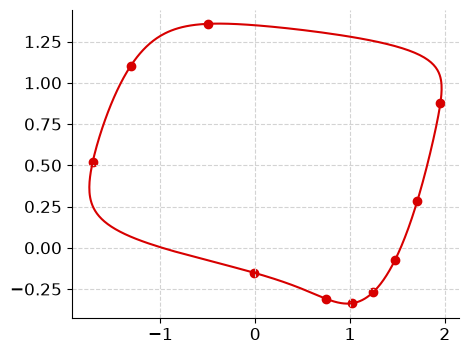

In [3]:
times, points = cycle.sample(512)
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(*points.T)
ax.scatter(*cycle.x0s.T)

In [4]:
for method in ("periodic_schur", "monodromy", "liouville"):
    fl = floquet(cycle, method=method)
    print(method, fl.multipliers, fl.exponents, fl.trivial_error, fl.closure)

periodic_schur [1.00000000e+00 1.69059036e-12] [ 5.39080812e-11 -2.41416251e+00] 6.05273831055797e-10 2.6581664292158038e-11
monodromy [1.00000000e+00 1.69042558e-12] [ 5.31331915e-11 -2.41417119e+00] 5.965734573010195e-10 None
liouville [1.00000000e+00 1.69059036e-12] [ 0.         -2.41416251] None None


# The asymptotic phase fields of fhn and fhn-easy

O3 by forward integration and a read-off on the cycle (`phase_grid`, route (a) of
`docs/design/analysis.md` §4). The cycle and phase 0 come from the isochron configs
(`isochron_cycle`), so the field, the AUTO isochrons and the model are compared on one
phase origin; `t_end` is the config's `phase_field.t_end`. Masked points are those
whose two readings, one period apart, differ by 1e-6 or more, or whose orbit has not
come within 1e-6 of the cycle: near the source, and wherever `t_end` falls short.
Run under float64 (first cell); on two CPU cores a 200 × 200 grid takes about a
minute per system.

In [5]:
import time
from pathlib import Path

import numpy as np
from deep_isochron.analysis.ode import asymptotic_phase, phase_grid
from deep_isochron.experiment.isochrons import (
    isochron_cycle,
    isochron_file,
    load_isochrons,
)
from hydra import compose, initialize_config_dir


def isochron_config(name):
    with initialize_config_dir(
        config_dir=str(Path("configs").resolve()), version_base=None
    ):
        return compose(config_name=f"isochrons/{name}")


xs = ys = jnp.linspace(-3.0, 3.0, 200)
fields = {}
for name in ("fhn", "fhn-easy"):
    cfg = isochron_config(name)
    cycle = isochron_cycle(cfg)
    start = time.perf_counter()
    field, mask, result = phase_grid(cycle, xs, ys, t_end=cfg.phase_field.t_end)

    fields[name] = (cfg, cycle, np.asarray(field), np.asarray(mask), result)
    print(
        f"{name}: T = {float(cycle.period):.6f}, masked {int((~mask).sum())} of "
        f"{mask.size}, {time.perf_counter() - start:.0f} s"
    )

fhn: T = 11.227887, masked 0 of 40000, 238 s
fhn-easy: T = 10.832945, masked 0 of 40000, 285 s


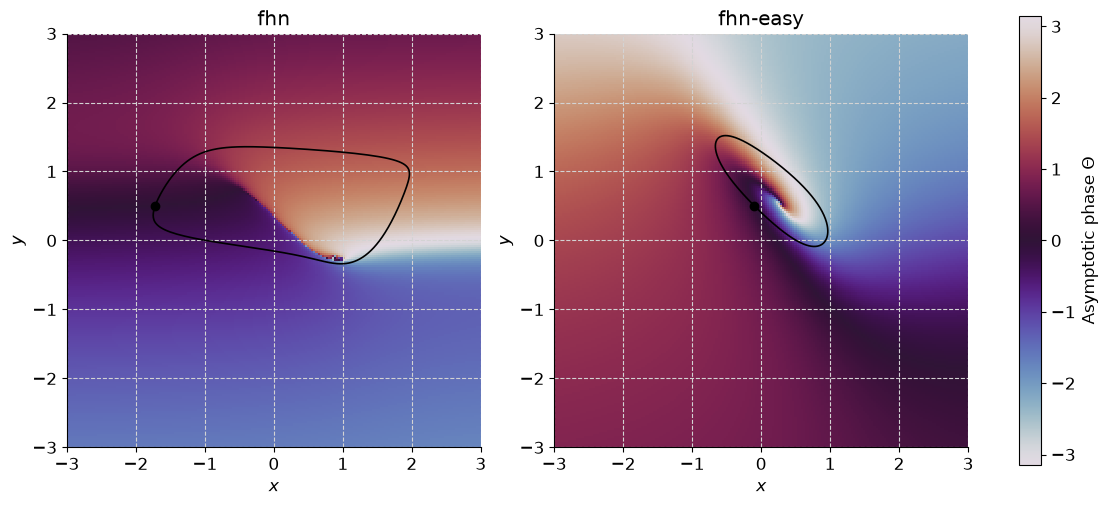

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, (name, (cfg, cycle, field, mask, _)) in zip(axes, fields.items(), strict=True):
    ax.set_facecolor("0.6")  # masked points
    image = ax.pcolormesh(
        xs, ys, field, cmap="twilight", vmin=-np.pi, vmax=np.pi, shading="nearest"
    )
    if isochron_file(cfg).exists():
        for iso in load_isochrons(cfg).isochrons[::10]:
            ax.plot(*iso.points.T, color="w", lw=0.6)
    _, points = cycle.sample(512)
    ax.plot(*np.asarray(points).T, color="k", lw=1.2)
    ax.plot(*np.asarray(cycle.x0s[0]), "ko")
    ax.set(title=name, xlabel="$x$", ylabel="$y$", aspect="equal")
    ax.set(xlim=(xs[0], xs[-1]), ylim=(ys[0], ys[-1]))
fig.colorbar(image, ax=axes, label=r"Asymptotic phase $\Theta$")

Check against AUTO (when the config's `.nc` exists): the phase at the points of each
isochron within 0.01 of the cycle, against the isochron's phase. Farther out, near the
source, a stored point's position error times the steep phase gradient there grows
to a radian (`tests/test_phase.py`).

In [ ]:
for name, (cfg, cycle, *_) in fields.items():
    if not isochron_file(cfg).exists():
        print(f"{name}: no isochron file at {isochron_file(cfg)}")
        continue
    _, samples = cycle.sample(4096)
    read = jax.jit(
        jax.vmap(lambda x: asymptotic_phase(cycle, x, t_end=cfg.phase_field.t_end))
    )
    gaps = []
    for iso in load_isochrons(cfg).isochrons:
        d = np.linalg.norm(iso.points[:, None] - np.asarray(samples)[None], axis=2)
        near = iso.points[d.min(axis=1) < 0.01]
        if len(near):
            phase = np.asarray(read(jnp.asarray(near)).phase)
            gaps.append(np.abs(np.angle(np.exp(1j * (phase - iso.phase)))).max())
    print(f"{name}: {len(gaps)} isochrons, largest gap {max(gaps):.2e} rad")

Comparison with a trained model. Fill in the run directories. A model's phase has its
own origin and may run either way round the cycle, so the reference is aligned to it
by a circular-mean offset for each direction, and the direction with the smaller
residual is kept. `load_model` applies the run's own `x64` and device settings, so the
reference fields above are computed first and kept as NumPy arrays.

fhn: sense -1, offset -2.3991 rad max 3.059e+00 rad
fhn-easy: sense -1, offset -0.5474 rad max 3.122e+00 rad


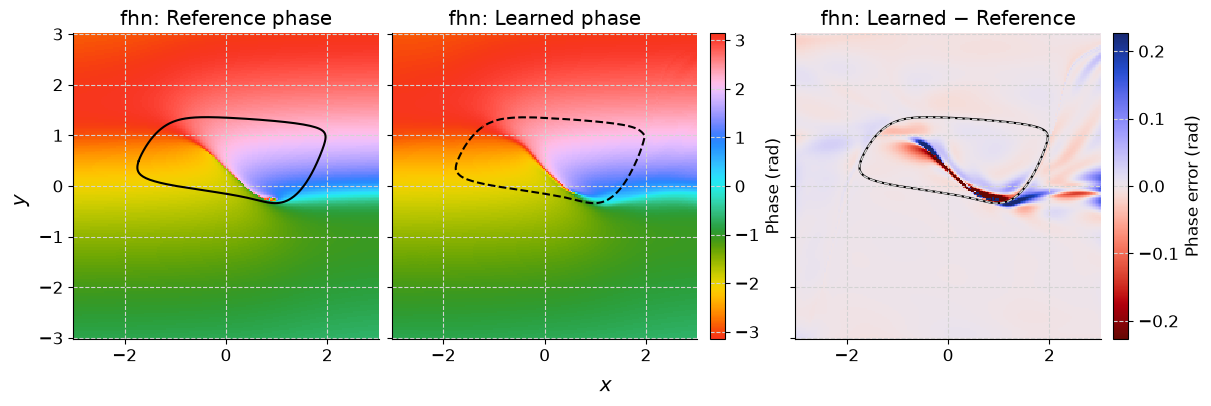

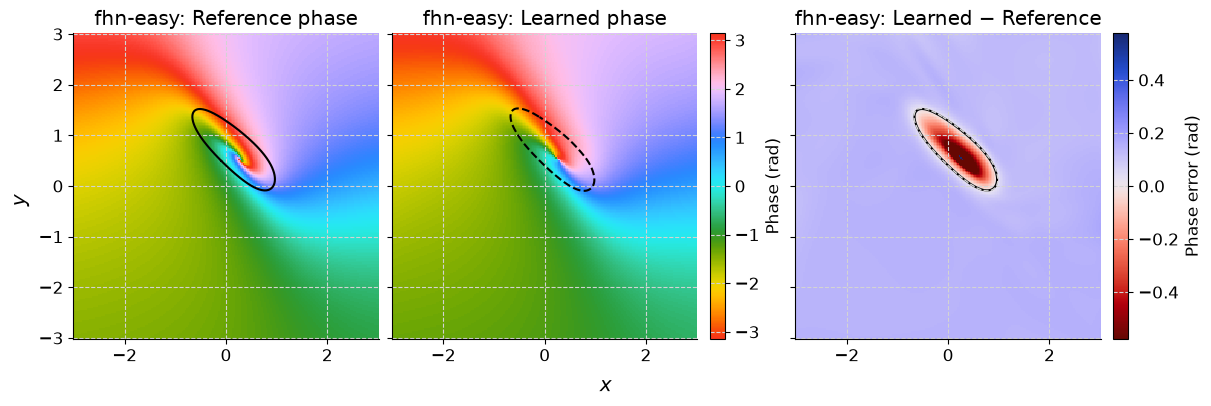

In [ ]:
import colorcet as cc
from deep_isochron.experiment.run import load_model


RUN_DIRS = {
    "fhn": "./runs/fhn2",
    "fhn-easy": "./runs/fhn_easy",
}  # the run directories of the trained models


def wrap(angle):
    return np.angle(np.exp(1j * angle))


def align(model_phase, reference):
    """(sense, offset, residual) with model ≈ sense · reference + offset."""
    best = None
    for sense in (1.0, -1.0):
        offset = np.angle(np.nanmean(np.exp(1j * (model_phase - sense * reference))))
        residual = wrap(model_phase - sense * reference - offset)
        rms = np.sqrt(np.nanmean(residual**2))
        if best is None or rms < best[3]:
            best = (sense, offset, residual, rms)
    return best


def model_phase_origin(model, cycle, n=1024, newton_steps=8):
    """(theta0, sense): the model's phase where its cycle crosses the reference
    section `cycle.section` in the direction of the flow, and the sign of its
    phase velocity."""
    sense = jnp.sign(model.latent_dynamics.omega())

    def s(theta):
        return cycle.section.signed_distance(model.cycle_point(theta))

    thetas = jnp.linspace(-jnp.pi, jnp.pi, n, endpoint=False)
    vals = jax.vmap(s)(thetas)
    nxt = jnp.roll(vals, -1)
    forward = (vals * nxt <= 0) & (sense * (nxt - vals) > 0)
    if not bool(forward.any()):
        raise ValueError("the learned cycle does not cross the reference section.")
    dist = jnp.linalg.norm(jax.vmap(model.cycle_point)(thetas) - cycle.x0s[0], axis=1)
    theta = thetas[jnp.argmin(jnp.where(forward, dist, jnp.inf))]
    for _ in range(newton_steps):
        theta = theta - s(theta) / jax.grad(s)(theta)
    return float(wrap(theta)), float(sense)


grid = np.stack(np.meshgrid(np.asarray(xs), np.asarray(ys)), axis=-1).reshape(-1, 2)
for name, run_dir in RUN_DIRS.items():
    if run_dir is None:
        continue
    cfg, cycle, field, mask, _ = fields[name]
    model = load_model(run_dir)
    model_phase = np.asarray(jax.vmap(model.phase)(jnp.asarray(grid)))
    model_phase = model_phase.reshape(field.shape)

    theta0, sense = model_phase_origin(model, cycle)
    residual = wrap(model_phase - sense * field - theta0)
    print(
        f"{name}: sense {sense:+.0f}, offset {theta0:.4f} rad "
        f"max {np.nanmax(np.abs(residual)):.3e} rad"
    )
    fig, axes = plt.subplots(
        1, 3, figsize=(12, 4), constrained_layout=True, sharey=True
    )
    panels = (
        ("Reference phase", wrap(sense * field + theta0), cc.cm.CET_C6, np.pi),
        ("Learned phase", np.where(mask, model_phase, np.nan), cc.cm.CET_C6, np.pi),
        (
            "Learned − Reference",
            residual,
            cc.cm.CET_D1A_r,
            np.nanpercentile(np.abs(residual), 99.5),
        ),
    )
    images = []
    for ax, (title, data, cmap, limit) in zip(axes, panels, strict=True):
        ax.set_facecolor("0.6")
        img = ax.pcolormesh(
            xs, ys, data, cmap=cmap, vmin=-limit, vmax=limit, shading="nearest"
        )
        images.append(img)
        ax.set(title=f"{name}: {title}", aspect="equal")

    # Plot true limit cycle
    _, points = cycle.sample(512)
    axes[0].plot(*np.asarray(points).T, color="k", lw=1.5)

    # Plot learned limit cycle
    pts_learned = jax.vmap(model.cycle_point)(
        jnp.linspace(-jnp.pi, jnp.pi, 512, endpoint=False)
    )
    axes[1].plot(*np.asarray(pts_learned).T, color="k", lw=1.5, ls="--")

    # Plot both cycles on the residual panel
    axes[2].plot(*np.asarray(points).T, color="k", lw=1.5)
    axes[2].plot(*np.asarray(pts_learned).T, color="lightgrey", lw=1.0, ls="--")

    cax_phase = axes[1].inset_axes([1.04, 0, 0.05, 1])
    cax_residual = axes[2].inset_axes([1.04, 0, 0.05, 1])
    cbar_phase = fig.colorbar(
        images[0],
        ax=axes[:2],
        cax=cax_phase,
    )
    cbar_phase.set_label(label="Phase (rad)", fontsize="medium")
    cbar_residual = fig.colorbar(
        images[2],
        ax=axes[2],
        cax=cax_residual,
    )
    cbar_residual.set_label(label="Phase error (rad)", fontsize="medium")

    if isochron_file(cfg).exists():  # an isochron is a level set of the model's phase
        spreads = []
        for iso in load_isochrons(cfg).isochrons:
            phase = np.asarray(jax.vmap(model.phase)(jnp.asarray(iso.points)))
            spreads.append(np.abs(wrap(phase - sense * iso.phase - theta0)).max())
        print(
            f"  on the AUTO isochrons: median gap {np.median(spreads):.3e}, "
            f"max {max(spreads):.3e} rad"
        )

    fig.supxlabel("$x$")
    fig.supylabel("$y$")

In [30]:
def learned_isochron(model, theta, r):
    """H⁻¹ of the normal form's isochron of phase `theta`, sampled at radii `r`."""
    return jax.vmap(model.bijection.inverse)(model.latent_dynamics.isochron(theta, r))

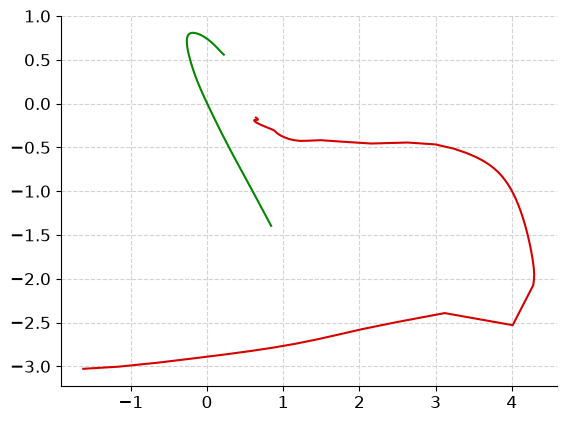

In [37]:
for name, run_dir in RUN_DIRS.items():
    if run_dir is None:
        continue
    # cfg, cycle, field, mask, _ = fields[name]
    model = load_model(run_dir)

    iso_learned = learned_isochron(model, -0.25 * jnp.pi, jnp.linspace(0.1, 2, 100))
    plt.plot(*iso_learned.T)

## Compute reference isochrons and compare against the model

In [49]:
from deep_isochron.experiment.isochrons import compute_isochrons


def isochron_config(name, *overrides):
    with initialize_config_dir(
        config_dir=str(Path("configs").resolve()), version_base=None
    ):
        return compose(config_name=f"isochrons/{name}", overrides=list(overrides))


N_ISOCHRONS = 5  # phases 2πk/5 wrapped to (−π, π]; their own file, by the config hash

references = {}
for name in ("fhn", "fhn-easy"):  # "fhn-easy"):
    cfg = isochron_config(name, f"phases.count={N_ISOCHRONS}")
    if isochron_file(cfg).exists():
        foliation = load_isochrons(cfg)
    else:
        start = time.perf_counter()
        foliation = compute_isochrons(cfg)  # AUTO-07p, one CPU worker per phase
        print(
            f"{name}: traced in {time.perf_counter() - start:.0f} s, "
            f"saved to {isochron_file(cfg)}"
        )
    for failure in foliation.failures:
        print(f"{name}: phase {failure.phase:+.4f} failed: {failure.message}")
    references[name] = foliation

fhn-easy: traced in 128 s, saved to data/isochrons/fitzhugh_nagumo_easy-271f3221.nc


fhn: sense -1, theta0 -2.3991 rad
  phase +0.000: gap on the AUTO points, median 2.27e+00, max 2.78e+00 rad
  phase +1.257: gap on the AUTO points, median 2.75e+00, max 3.14e+00 rad
  phase +2.513: gap on the AUTO points, median 1.50e+00, max 2.59e+00 rad
  phase -2.513: gap on the AUTO points, median nan, max nan rad
  phase -1.257: gap on the AUTO points, median 1.02e+00, max 2.44e+00 rad
fhn-easy: sense -1, theta0 -0.5474 rad
  phase +0.000: gap on the AUTO points, median 2.31e-01, max 1.57e+00 rad
  phase +1.257: gap on the AUTO points, median 2.37e-01, max 1.72e+00 rad
  phase +2.513: gap on the AUTO points, median 2.61e-01, max 1.13e+00 rad
  phase -2.513: gap on the AUTO points, median 1.66e-01, max 1.52e+00 rad
  phase -1.257: gap on the AUTO points, median 1.85e-01, max 1.56e+00 rad


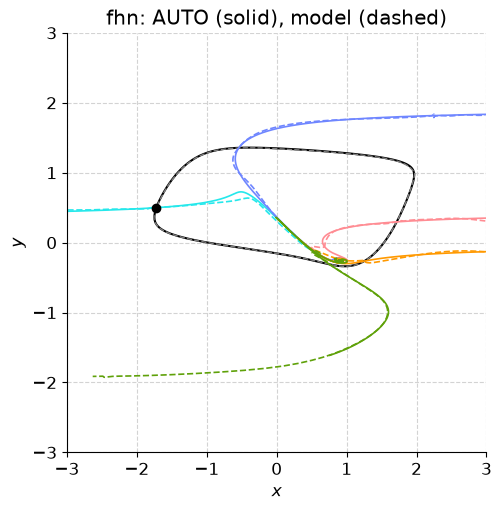

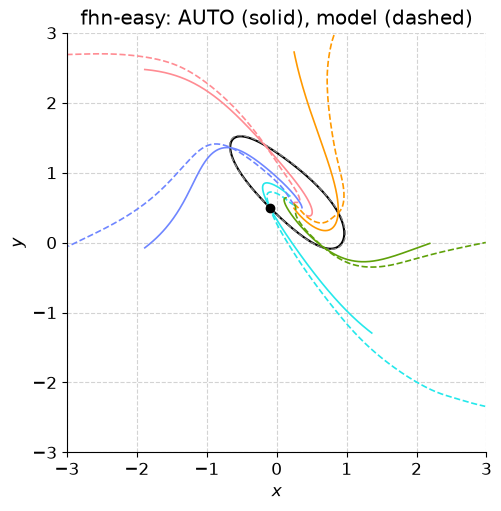

In [50]:
r_inner = jnp.geomspace(1e-4, 1.0, 400, endpoint=False)  # the spiral onto H⁻¹(0)
lo, hi = float(xs[0]), float(xs[-1])

for name, run_dir in RUN_DIRS.items():
    foliation = references[name]
    cycle = foliation.cycle
    model = load_model(run_dir)
    theta0, sense = model_phase_origin(model, cycle)

    # Radii: out past the latent image of the plotting window
    r_max = 1.1 * float(
        jnp.max(jnp.linalg.norm(jax.vmap(model.bijection)(jnp.asarray(grid)), axis=1))
    )
    r = jnp.concatenate((r_inner, jnp.geomspace(1.0, r_max, 400)))

    fig, ax = plt.subplots(figsize=(5.5, 5), constrained_layout=True)
    _, points = cycle.sample(512)
    ax.plot(*np.asarray(points).T, color="k", lw=1.5)
    learned_cycle = jax.vmap(model.cycle_point)(
        jnp.linspace(-jnp.pi, jnp.pi, 512, endpoint=False)
    )
    ax.plot(*np.asarray(learned_cycle).T, color="0.5", lw=1.0, ls="--")

    print(f"{name}: sense {sense:+.0f}, theta0 {theta0:+.4f} rad")
    for iso in foliation.isochrons:
        theta = wrap(sense * iso.phase + theta0)  # the model's phase of this isochron
        color = cc.cm.CET_C6((iso.phase + np.pi) / (2 * np.pi))

        ax.plot(*iso.points.T, color=color, lw=1.2)
        learned = np.array(learned_isochron(model, jnp.asarray(theta), r))
        learned[((learned < lo) | (learned > hi)).any(axis=1)] = np.nan
        ax.plot(*learned.T, color=color, lw=1.2, ls="--")

        # Is the AUTO isochron a level set of the model's phase?
        gap = np.abs(
            wrap(np.asarray(jax.vmap(model.phase)(jnp.asarray(iso.points))) - theta)
        )
        print(
            f"  phase {iso.phase:+.3f}: gap on the AUTO points, "
            f"median {np.median(gap):.2e}, max {gap.max():.2e} rad"
        )

    ax.plot(*np.asarray(cycle.x0s[0]), "ko")  # phase 0, on the reference section
    ax.set(
        title=f"{name}: AUTO (solid), model (dashed)",
        xlabel="$x$",
        ylabel="$y$",
        xlim=(lo, hi),
        ylim=(lo, hi),
        aspect="equal",
    )

In [ ]:
from string import ascii_uppercase

from matplotlib.collections import LineCollection


def equilibrium(ode, guess, steps=30):
    """The equilibrium of `ode` near `guess`, by Newton's method on the field."""
    f = lambda x: ode.rhs(0.0, x)
    x = jnp.asarray(guess, dtype=float)
    for _ in range(steps):
        x = x - jnp.linalg.solve(jax.jacfwd(f)(x), f(x))
    if not float(jnp.linalg.norm(f(x))) < 1e-12:
        raise ValueError(
            f"Newton did not converge from {guess}: "
            f"|f| = {float(jnp.linalg.norm(f(x))):.1e}"
        )
    return np.asarray(x)


def matched_points(model, theta, points):
    """The learned isochron of model phase `theta` at the model amplitude of each of
    `points`: Θ_m = theta and |H(q_i)| = |H(p_i)|, so p_i − q_i is the model's phase
    error at p_i expressed as a displacement along its isostable curve."""
    radii = jnp.linalg.norm(jax.vmap(model.bijection)(jnp.asarray(points)), axis=1)
    latent = model.latent_dynamics.isochron(theta, radii)
    return np.array(jax.vmap(model.bijection.inverse)(latent))


def log_polar(points, center):
    """(log10 distance, unwrapped angle in turns) of `points` about `center`, along
    the curve."""
    d = points - center
    return np.log10(np.hypot(*d.T)), np.unwrap(np.arctan2(d[:, 1], d[:, 0])) / (
        2 * np.pi
    )


def hairpins(turns, min_excursion=0.05):
    """Indices of the reversals of the unwrapped angle `turns` along a curve: its local
    extrema, keeping one only when its angle differs from the last kept one (or the
    start) by more than `min_excursion` turns, so that a wiggle is not a hairpin."""
    extrema = np.flatnonzero(np.diff(np.sign(np.diff(turns)))) + 1
    kept, last = [], 0
    for i in extrema:
        if abs(turns[i] - turns[last]) > min_excursion:
            kept.append(i)
            last = i
    return np.asarray(kept, dtype=int)


def colored_curve(ax, points, values, cmap, norm, **kwargs):
    """Plot `points` as a curve colored by `values` along it."""
    segments = np.stack([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap=cmap, norm=norm, **kwargs)
    lc.set_array(0.5 * (values[:-1] + values[1:]))
    return ax.add_collection(lc)

fhn: isochron 2 at phase +2.513; |H⁻¹(0) − q| = 0.375; 9 hairpins at A: L -3.237, log r -3.90, B: L -3.229, log r -3.19, C: L -3.224, log r -2.87, D: L -3.187, log r -2.13, E: L -3.157, log r -2.08, F: L -2.999, log r -1.39, G: L -2.871, log r -1.66, H: L -2.100, log r -0.46, I: L -1.273, log r -0.60
fhn-easy: isochron 3 at phase -2.513; |H⁻¹(0) − q| = 0.028; 1 hairpins at A: L +0.000, log r -0.21


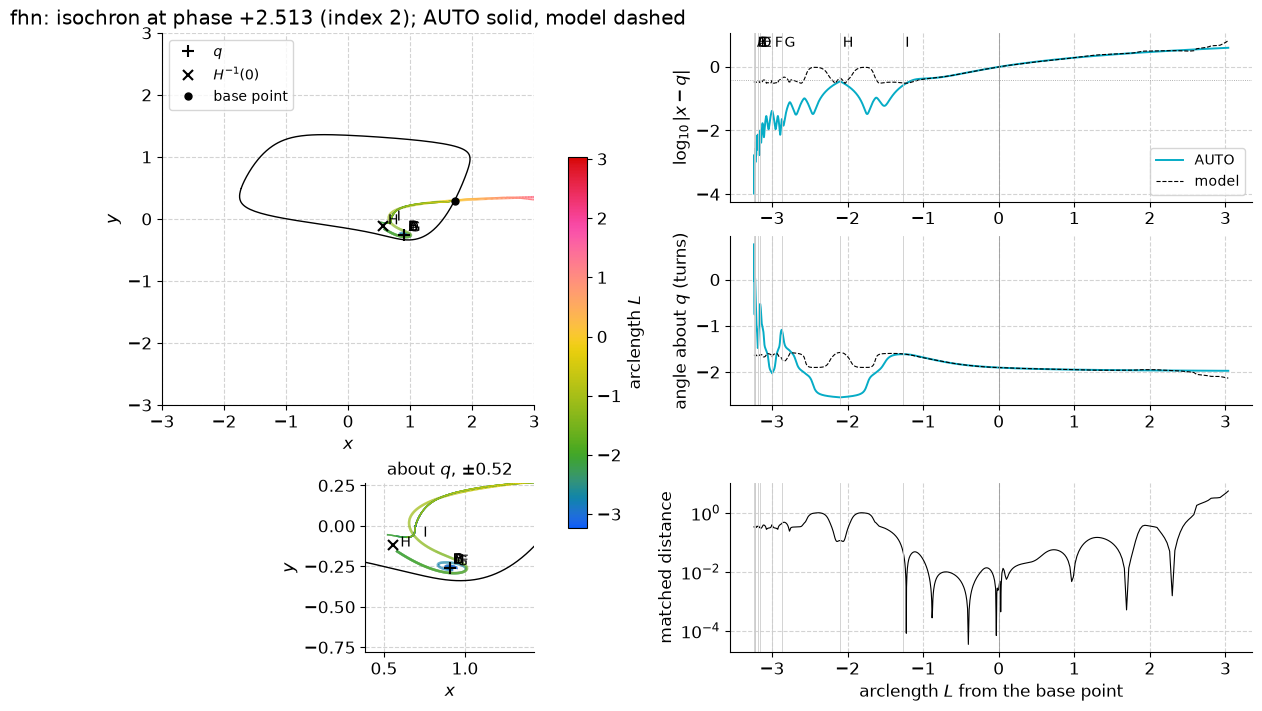

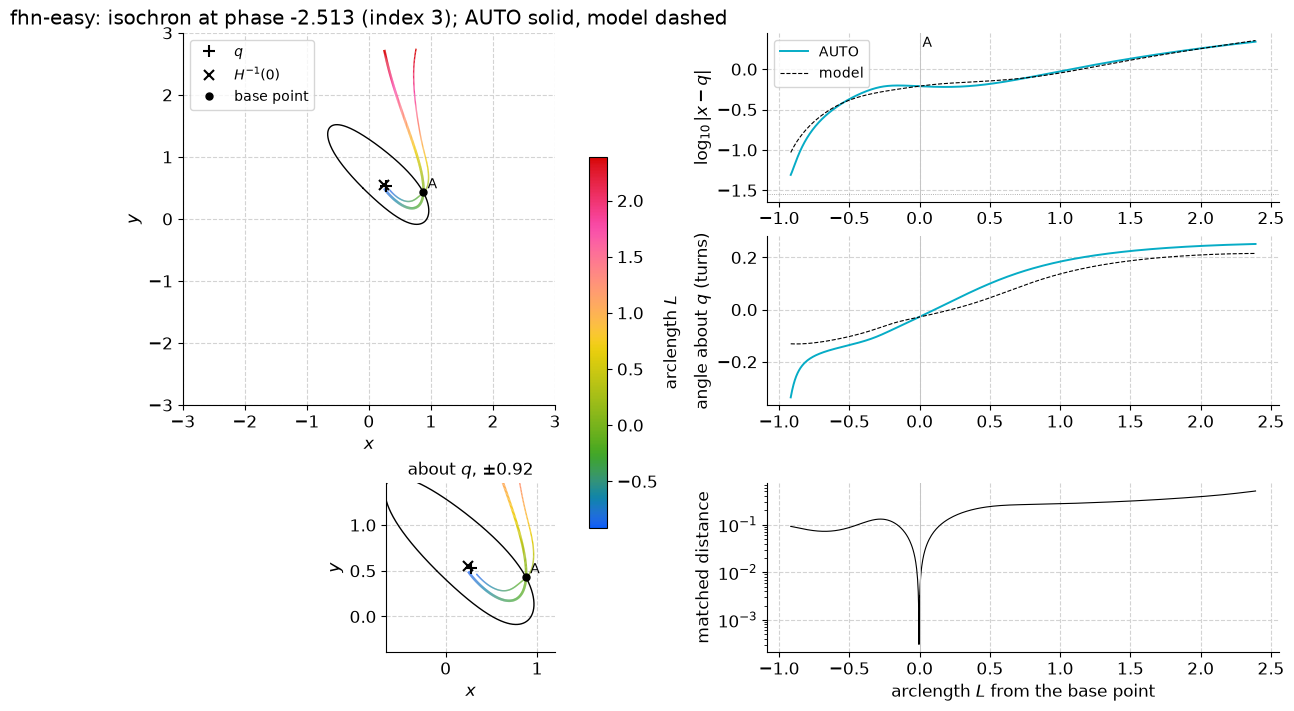

In [53]:
ISO_INDEX = None  # None: the isochron that comes closest to the equilibrium
MIN_EXCURSION = 0.05  # turns; a smaller reversal of the angle is not a hairpin
ZOOM_HALF = None  # half-width of the zoom about q; None: 1.5 × the farthest hairpin

for name, run_dir in RUN_DIRS.items():
    foliation = references[name]
    cycle = foliation.cycle
    q = equilibrium(cycle.ode, np.asarray(cycle.sample(512)[1]).mean(axis=0))
    model = load_model(run_dir)
    theta0, sense = model_phase_origin(model, cycle)
    q_model = np.asarray(
        model.bijection.inverse(jnp.zeros(2))
    )  # the model's equilibrium

    isos = foliation.isochrons
    k = (
        int(np.argmin([np.linalg.norm(iso.points - q, axis=1).min() for iso in isos]))
        if ISO_INDEX is None
        else ISO_INDEX
    )
    iso = isos[k]
    theta = wrap(sense * iso.phase + theta0)
    L = iso.arclength
    matched = matched_points(model, theta, iso.points)
    error = np.linalg.norm(iso.points - matched, axis=1)
    rho_ref, phi_ref = log_polar(iso.points, q)
    rho_m, phi_m = log_polar(matched, q)
    phi_m += np.round(phi_ref[np.argmin(np.abs(L))] - phi_m[np.argmin(np.abs(L))])

    tips = hairpins(phi_ref, MIN_EXCURSION)
    labels = ascii_uppercase[: len(tips)]
    print(
        f"{name}: isochron {k} at phase {iso.phase:+.3f}; |H⁻¹(0) − q| = "
        f"{np.linalg.norm(q_model - q):.3f}; {len(tips)} hairpins at "
        + ", ".join(
            f"{labels[i]}: L {L[t]:+.3f}, log r {rho_ref[t]:.2f}"
            for i, t in enumerate(tips)
        )
    )

    norm = plt.Normalize(L.min(), L.max())
    cmap = cc.cm.CET_R3
    fig = plt.figure(figsize=(13, 7), constrained_layout=True)
    grid = fig.add_gridspec(3, 2, width_ratios=[1.1, 1])
    ax_full = fig.add_subplot(grid[:2, 0])
    ax_zoom = fig.add_subplot(grid[2, 0])
    ax_rho = fig.add_subplot(grid[0, 1])
    ax_phi = fig.add_subplot(grid[1, 1], sharex=ax_rho)
    ax_err = fig.add_subplot(grid[2, 1], sharex=ax_rho)

    # the plane, full and zoomed about q
    _, cyc = cycle.sample(512)
    half = ZOOM_HALF or (
        1.5 * np.max(np.linalg.norm(iso.points[tips] - q, axis=1)) if len(tips) else 0.2
    )
    for ax, (lo_, hi_) in (
        (ax_full, (float(xs[0]), float(xs[-1]))),
        (ax_zoom, (-half, half)),
    ):
        center = np.zeros(2) if ax is ax_full else q
        ax.plot(*np.asarray(cyc).T, color="k", lw=1.0)
        colored_curve(ax, iso.points, L, cmap, norm, lw=1.8)
        colored_curve(ax, matched, L, cmap, norm, lw=1.0, linestyles="--")
        ax.plot(*q, "k+", ms=9, mew=1.5, label="$q$")
        ax.plot(*q_model, "kx", ms=7, mew=1.5, label="$H^{-1}(0)$")
        ax.plot(*iso.base_point, "ko", ms=5, label="base point")
        for i, t in enumerate(tips):
            ax.annotate(
                labels[i],
                iso.points[t],
                xytext=(3, 3),
                textcoords="offset points",
                fontsize="small",
            )
        ax.set(
            xlim=(center[0] + lo_, center[0] + hi_),
            ylim=(center[1] + lo_, center[1] + hi_),
            aspect="equal",
            xlabel="$x$",
            ylabel="$y$",
        )
    ax_full.legend(loc="upper left", fontsize="small")
    ax_full.set_title(
        f"{name}: isochron at phase {iso.phase:+.3f} (index {k}); "
        "AUTO solid, model dashed"
    )
    ax_zoom.set_title(f"about $q$, ±{half:.2g}", fontsize="medium")
    fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=[ax_full, ax_zoom],
        label="arclength $L$",
        shrink=0.6,
    )

    # polar coordinates about q and the matched distance, against L
    for ax, (a, b) in zip((ax_rho, ax_phi), ((rho_ref, rho_m), (phi_ref, phi_m))):
        ax.plot(L, a, color="C3", lw=1.4, label="AUTO")
        ax.plot(L, b, color="k", lw=0.8, ls="--", label="model")
    ax_rho.axhline(np.log10(np.linalg.norm(q_model - q)), color="0.6", lw=0.6, ls=":")
    ax_rho.set(ylabel=r"$\log_{10}|x - q|$")
    ax_rho.legend(loc="best", fontsize="small")
    ax_phi.set(ylabel="angle about $q$ (turns)")
    ax_err.semilogy(L, error, color="k", lw=0.8)
    ax_err.set(ylabel="matched distance", xlabel="arclength $L$ from the base point")
    for ax in (ax_rho, ax_phi, ax_err):
        ax.axvline(0.0, color="0.6", lw=0.6)
        for t in tips:
            ax.axvline(L[t], color="0.8", lw=0.6)
    for i, t in enumerate(tips):
        ax_rho.annotate(
            labels[i],
            (L[t], 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(2, -10),
            textcoords="offset points",
            fontsize="small",
        )